<a href="https://colab.research.google.com/github/mugume-atwiine/CMMS/blob/main/lfd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install h5py numpy matplotlib torch scikit-learn

In [2]:
from google.colab import files

uploaded = files.upload()


Saving demo.hdf5 to demo.hdf5


In [3]:
import h5py
import numpy as np

file_path = "/content/demo.hdf5"

f = h5py.File(file_path, "r")

print("Available demonstrations:")
print(list(f["data"].keys()))

print("Number of demonstrations:",
      len(f["data"].keys()))

Available demonstrations:
['demo_1', 'demo_10', 'demo_11', 'demo_12', 'demo_13', 'demo_14', 'demo_15', 'demo_16', 'demo_17', 'demo_18', 'demo_19', 'demo_2', 'demo_20', 'demo_21', 'demo_22', 'demo_23', 'demo_24', 'demo_25', 'demo_26', 'demo_27', 'demo_28', 'demo_29', 'demo_3', 'demo_30', 'demo_31', 'demo_32', 'demo_33', 'demo_34', 'demo_35', 'demo_36', 'demo_37', 'demo_38', 'demo_39', 'demo_4', 'demo_40', 'demo_41', 'demo_42', 'demo_43', 'demo_44', 'demo_45', 'demo_46', 'demo_47', 'demo_48', 'demo_49', 'demo_5', 'demo_50', 'demo_51', 'demo_52', 'demo_53', 'demo_54', 'demo_55', 'demo_56', 'demo_57', 'demo_58', 'demo_59', 'demo_6', 'demo_60', 'demo_61', 'demo_62', 'demo_63', 'demo_64', 'demo_65', 'demo_66', 'demo_67', 'demo_68', 'demo_69', 'demo_7', 'demo_70', 'demo_71', 'demo_72', 'demo_73', 'demo_74', 'demo_75', 'demo_76', 'demo_77', 'demo_8', 'demo_9']
Number of demonstrations: 77


In [4]:
states = []
actions = []

demo_names = sorted(
    f["data"].keys(),
    key=lambda x: int(x.split("_")[1])
)

for demo_name in demo_names:

    demo = f["data"][demo_name]

    demo_states = demo["states"][:]
    demo_actions = demo["actions"][:]

    states.append(demo_states)
    actions.append(demo_actions)

states = np.concatenate(states, axis=0)
actions = np.concatenate(actions, axis=0)

print("States shape:", states.shape)
print("Actions shape:", actions.shape)

States shape: (24812, 71)
Actions shape: (24812, 7)


In [5]:
from sklearn.model_selection import train_test_split
import numpy as np

# First split: 70% training, 30% remaining
train_demos, remaining_demos = train_test_split(
    demo_names,
    test_size=0.30,
    random_state=42
)

# Second split: 15% validation, 15% testing
val_demos, test_demos = train_test_split(
    remaining_demos,
    test_size=0.50,
    random_state=42
)

print("Training demonstrations:", len(train_demos))
print("Validation demonstrations:", len(val_demos))
print("Testing demonstrations:", len(test_demos))

Training demonstrations: 53
Validation demonstrations: 12
Testing demonstrations: 12


In [6]:
def extract_data(demo_list):

    X = []
    Y = []

    for d in demo_list:

        demo = f["data"][d]

        X.append(demo["states"][:])
        Y.append(demo["actions"][:])

    return np.concatenate(X), np.concatenate(Y)


# Training data
X_train, Y_train = extract_data(train_demos)

# Validation data
X_val, Y_val = extract_data(val_demos)

# Testing data
X_test, Y_test = extract_data(test_demos)


print("Training:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Testing:", X_test.shape, Y_test.shape)

Training: (17197, 71) (17197, 7)
Validation: (3809, 71) (3809, 7)
Testing: (3806, 71) (3806, 7)


In [7]:
# State normalization
state_mean = X_train.mean(axis=0)
state_std = X_train.std(axis=0)

state_std[state_std < 1e-6] = 1.0

X_train = (X_train - state_mean) / state_std
X_val = (X_val - state_mean) / state_std
X_test = (X_test - state_mean) / state_std


# Action normalization
action_mean = Y_train.mean(axis=0)
action_std = Y_train.std(axis=0)

action_std[action_std < 1e-6] = 1.0

Y_train = (Y_train - action_mean) / action_std
Y_val = (Y_val - action_mean) / action_std
Y_test = (Y_test - action_mean) / action_std

print("Normalization completed!")

Normalization completed!


In [8]:
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

# Convert datasets to tensors
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(Y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(Y_val, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False
)


criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 100

train_losses = []
val_losses = []

for epoch in range(epochs):

    # Training phase
    model.train()
    train_loss = 0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        predictions = model(batch_x)

        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation phase
    model.eval()
    val_loss = 0

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            predictions = model(batch_x)

            loss = criterion(predictions, batch_y)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Training Loss: {train_loss:.6f} | "
            f"Validation Loss: {val_loss:.6f}"
        )

NameError: name 'model' is not defined

In [9]:
import torch
import torch.nn as nn

class BCPolicy(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(71, 256),
            nn.ReLU(),

            nn.Linear(256, 256),
            nn.ReLU(),

            nn.Linear(256, 7)
        )

    def forward(self, x):
        return self.network(x)

In [10]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = BCPolicy().to(device)

print(model)

BCPolicy(
  (network): Sequential(
    (0): Linear(in_features=71, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=7, bias=True)
  )
)


In [11]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model and optimizer initialized successfully!")

Model and optimizer initialized successfully!


In [12]:
epochs = 100

train_losses = []
val_losses = []

# Continue with your existing training loop

In [13]:
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

# Convert datasets to tensors
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(Y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(Y_val, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False
)


criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 100

train_losses = []
val_losses = []

for epoch in range(epochs):

    # Training phase
    model.train()
    train_loss = 0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        predictions = model(batch_x)

        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation phase
    model.eval()
    val_loss = 0

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            predictions = model(batch_x)

            loss = criterion(predictions, batch_y)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Training Loss: {train_loss:.6f} | "
            f"Validation Loss: {val_loss:.6f}"
        )

Epoch 10/100 | Training Loss: 0.143204 | Validation Loss: 0.157850
Epoch 20/100 | Training Loss: 0.133156 | Validation Loss: 0.159193
Epoch 30/100 | Training Loss: 0.127047 | Validation Loss: 0.162013
Epoch 40/100 | Training Loss: 0.121451 | Validation Loss: 0.171867
Epoch 50/100 | Training Loss: 0.117898 | Validation Loss: 0.175130
Epoch 60/100 | Training Loss: 0.114857 | Validation Loss: 0.183394
Epoch 70/100 | Training Loss: 0.111081 | Validation Loss: 0.192970
Epoch 80/100 | Training Loss: 0.107077 | Validation Loss: 0.197656
Epoch 90/100 | Training Loss: 0.103701 | Validation Loss: 0.208931
Epoch 100/100 | Training Loss: 0.098624 | Validation Loss: 0.220104


In [15]:
model.eval()

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).to(device)

Y_test_tensor = torch.tensor(
    Y_test,
    dtype=torch.float32
).to(device)

with torch.no_grad():

    predictions = model(X_test_tensor)

    test_loss = criterion(
        predictions,
        Y_test_tensor
    ).item()

print("Final Test MSE:", test_loss)

Final Test MSE: 0.16710880398750305


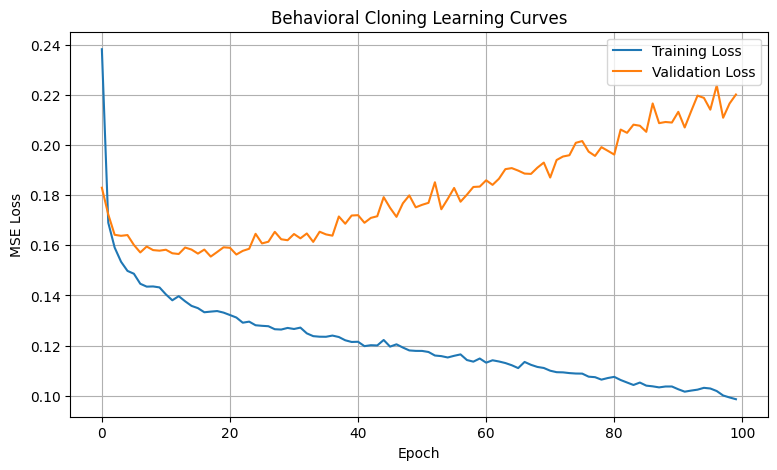

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title("Behavioral Cloning Learning Curves")

plt.legend()
plt.grid()

plt.show()

In [16]:

import copy
import torch
import torch.nn as nn

# Reinitialize the model before retraining
model = BCPolicy().to(device)

criterion = nn.MSELoss()

# Add weight decay for regularization
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

epochs = 100
patience = 10
min_delta = 0.0001

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

best_model_state = None

for epoch in range(epochs):

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()
    train_loss = 0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        predictions = model(batch_x)
        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()
    val_loss = 0

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            predictions = model(batch_x)

            loss = criterion(predictions, batch_y)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # -------------------------
    # SAVE BEST MODEL
    # -------------------------
    if val_loss < best_val_loss - min_delta:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train: {train_loss:.5f} | "
        f"Validation: {val_loss:.5f}"
    )

    # -------------------------
    # EARLY STOPPING
    # -------------------------
    if epochs_without_improvement >= patience:

        print("Early stopping triggered!")
        break

# Restore best model
model.load_state_dict(best_model_state)

print("\nTraining completed!")
print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)


Epoch 1/100 | Train: 0.24097 | Validation: 0.18208
Epoch 2/100 | Train: 0.16953 | Validation: 0.17282
Epoch 3/100 | Train: 0.15990 | Validation: 0.16660
Epoch 4/100 | Train: 0.15415 | Validation: 0.16503
Epoch 5/100 | Train: 0.15091 | Validation: 0.16429
Epoch 6/100 | Train: 0.14875 | Validation: 0.16139
Epoch 7/100 | Train: 0.14747 | Validation: 0.16082
Epoch 8/100 | Train: 0.14535 | Validation: 0.16078
Epoch 9/100 | Train: 0.14338 | Validation: 0.15765
Epoch 10/100 | Train: 0.14252 | Validation: 0.15866
Epoch 11/100 | Train: 0.14020 | Validation: 0.15781
Epoch 12/100 | Train: 0.13950 | Validation: 0.15602
Epoch 13/100 | Train: 0.13939 | Validation: 0.16053
Epoch 14/100 | Train: 0.13868 | Validation: 0.15719
Epoch 15/100 | Train: 0.13813 | Validation: 0.15894
Epoch 16/100 | Train: 0.13791 | Validation: 0.16058
Epoch 17/100 | Train: 0.13573 | Validation: 0.15769
Epoch 18/100 | Train: 0.13537 | Validation: 0.15967
Epoch 19/100 | Train: 0.13465 | Validation: 0.16025
Epoch 20/100 | Train:

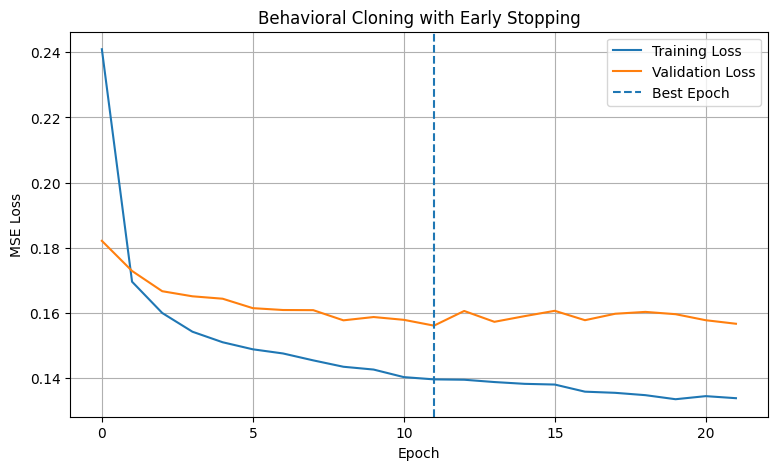

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.axvline(
    best_epoch - 1,
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.title("Behavioral Cloning with Early Stopping")

plt.legend()
plt.grid()

plt.show()

In [18]:
model.eval()

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
).to(device)

Y_test_tensor = torch.tensor(
    Y_test,
    dtype=torch.float32
).to(device)

with torch.no_grad():

    predictions = model(X_test_tensor)

    test_loss = criterion(
        predictions,
        Y_test_tensor
    ).item()

print("Best Validation MSE:", best_val_loss)
print("Final Test MSE:", test_loss)

Best Validation MSE: 0.15601967473824818
Final Test MSE: 0.15758271515369415
